# TD5 — Corrigé

Mini-projet pandas avec Our World in Data

Pour reproduire les résultats sans réseau, télécharger et extraire le dossier complet : il fournit data/gdp-per-capita-worldbank.csv et data/life-expectancy.csv, copiés sans modification depuis le dépôt. Lancer le script depuis ce dossier ou ouvrir le notebook à cet endroit. Le CSV OWID en ligne peut évoluer ; les résultats présentés proviennent de la copie locale dont la dernière année est 2025.

Exécuter toutes les cellules dans l’ordre, depuis une session neuve. Pour les données, extraire le dossier complet et ouvrir le notebook à sa racine. Les sorties sont celles d’une exécution de référence.

Bibliothèques : matplotlib ; pandas en plus au TD5.

In [1]:
# Afficher les figures dans le notebook.
%matplotlib inline

## Démarche en pseudo-code 1 — Pipeline pandas final

```text
# Objectif : mini-projet descriptif avec un CSV OWID
# 1. Lire le CSV
# 2. Inspecter lignes, colonnes et types
# 3. Renommer les colonnes utiles
# 4. Filtrer une annee et quelques pays
# 5. Calculer moyenne, mediane, min, max
# 6. Tracer un graphique lisible
# 7. Exporter un tableau propre
# 8. Rediger une interpretation prudente
```

Les exercices qui suivent mettent en œuvre ce plan, étape par étape.

## Démarche en pseudo-code 2 — Passer du tableau au graphique

```text
# Objectif : representer les dix valeurs les plus elevees
# Entree : tableau latest sans valeurs manquantes
# 1. Trier le tableau par PIB par habitant decroissant
# 2. Garder les dix premieres lignes
# 3. Tracer une barre par pays
# 4. Ajouter titre, axes et rotation des etiquettes
# 5. Sauvegarder la figure dans le dossier out
# Sortie : fichier gdp_top10.png
```

Les exercices qui suivent mettent en œuvre ce plan, étape par étape.

## Exercice 1 — Préparer le script

**Objectif.** Créer le dossier de sortie du mini-projet.

**Démarche.** Enregistrer le fichier dans le dossier TD5, ouvrir ce dossier dans VS Code, puis y lancer Python. exist_ok=True permet de réexécuter sans erreur si out existe déjà.

In [2]:
from pathlib import Path

out_dir = Path("out")
out_dir.mkdir(exist_ok=True)


**Résultat et interprétation.** Un dossier out existe dans le dossier courant. Les images et tableaux y seront enregistrés.

## Exercice 2 — Vérifier le dossier courant

**Objectif.** Vérifier le dossier courant.

**Démarche.** Afficher le lieu depuis lequel Python travaille, qui peut être différent du dossier où le script est enregistré.

In [3]:
print("Dossier courant :", Path.cwd())
print("Le dossier out existe :", out_dir.exists())
# Ces affichages de diagnostic peuvent être retirés après vérification.


Dossier courant : /private<dossier TD5 de cette exécution>
Le dossier out existe : True


**Résultat et interprétation.** Le premier chemin dépend de votre ordinateur ; le second affichage doit être True. Aucun chemin personnel n’est nécessaire dans le code.

## Exercice 3 — Lire le CSV OWID

**Objectif.** Lire et inspecter le CSV OWID.

**Démarche.** L’énoncé propose la lecture distante et autorise la lecture locale. La ligne distante est indiquée ci-dessous ; le corrigé exécute la copie du dépôt pour garantir les mêmes résultats hors connexion. Pour un essai en ligne, remplacer la ligne locale par la ligne commentée.

In [4]:
import pandas as pd

url = "https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv"
# Version en ligne de l'énoncé : df = pd.read_csv(url)
df = pd.read_csv("data/gdp-per-capita-worldbank.csv")
print(df.head())
print(df.shape)
print(df.columns)
# Copie locale fournie : 7445 lignes et 5 colonnes.


        Entity Code  Year  GDP per capita World region according to OWID
0  Afghanistan  AFG  2000       1617.8264                           Asia
1  Afghanistan  AFG  2001       1454.1108                           Asia
2  Afghanistan  AFG  2002       1774.3087                           Asia
3  Afghanistan  AFG  2003       1815.9282                           Asia
4  Afghanistan  AFG  2004       1776.9182                           Asia
(7445, 5)
Index(['Entity', 'Code', 'Year', 'GDP per capita',
       'World region according to OWID'],
      dtype='object')


**Résultat et interprétation.** La copie locale contient 7445 lignes et 5 colonnes. head affiche les cinq premières lignes ; shape donne (lignes, colonnes). Le fichier distant peut avoir d’autres dimensions.

## Exercice 4 — Repérer la colonne de l'indicateur

**Objectif.** Identifier la colonne numérique du PIB.

**Démarche.** Lire les noms avant de sélectionner la colonne. La dernière colonne du fichier local contient une région, et non le PIB.

In [5]:
print(list(df.columns))
print("Dernière colonne :", df.columns[-1])
# Le PIB de la copie fournie est dans "GDP per capita".
value_col = "GDP per capita"
print("Colonne du PIB :", value_col)
print("Type de cette colonne :", df[value_col].dtype)


['Entity', 'Code', 'Year', 'GDP per capita', 'World region according to OWID']
Dernière colonne : World region according to OWID
Colonne du PIB : GDP per capita
Type de cette colonne : float64


**Résultat et interprétation.** Colonnes : Entity, Code, Year, GDP per capita, World region according to OWID. df.columns[-1] renvoie la région : le raccourci de l’énoncé ne convient pas à ce fichier.

**Point de vigilance.** En ligne, le nom peut être plus long. Inspecter à nouveau df.columns et adapter value_col ; ne jamais renommer une région textuelle en gdp_pc.

## Exercice 5 — Renommer proprement

**Objectif.** Renommer les colonnes en conservant la bonne mesure.

**Démarche.** Réutiliser le nom vérifié à l’exercice 4, puis sélectionner trois colonnes pour contrôler le résultat.

In [6]:
df = df.rename(columns={
    "Entity": "country",
    "Code": "code",
    "Year": "year",
    value_col: "gdp_pc"
})
print(df[["country", "year", "gdp_pc"]].head())


       country  year     gdp_pc
0  Afghanistan  2000  1617.8264
1  Afghanistan  2001  1454.1108
2  Afghanistan  2002  1774.3087
3  Afghanistan  2003  1815.9282
4  Afghanistan  2004  1776.9182


**Résultat et interprétation.** country, year et gdp_pc sont disponibles. gdp_pc reste numérique. Les métadonnées OWID de cet indicateur annoncent des dollars internationaux aux prix de 2021, ajustés pour les différences de prix.

## Exercice 6 — Débogage pandas guidé

**Objectif.** Diagnostiquer quatre difficultés distinctes.

**Démarche.** Faire un contrôle ciblé avant de modifier le calcul : interpréteur, chemin, colonne, puis contenu du filtre.

In [7]:
# 1. ModuleNotFoundError : pandas n'est pas dans le Python utilisé.
#    Dans le terminal de cet environnement : python3 -m pip install pandas
# 2. FileNotFoundError : vérifier Path.cwd() et l'existence de data/le_fichier.csv.
print("CSV local présent :", Path("data/gdp-per-capita-worldbank.csv").exists())
# 3. KeyError 'gdp_pc' : vérifier le nom exact et relancer le renommage.
print("Colonnes après renommage :", list(df.columns))
# 4. selection vide : vérifier l'année, les données manquantes et les noms.
#    Les contrôles sur latest et selection arrivent aux exercices 7 à 9.


CSV local présent : True
Colonnes après renommage : ['country', 'code', 'year', 'gdp_pc', 'World region according to OWID']


**Résultat et interprétation.** Le chemin local existe et la liste des colonnes contient gdp_pc. Un tableau vide n’est pas nécessairement une exception Python.

## Exercice 7 — Sélectionner une année récente

**Objectif.** Sélectionner la dernière année du fichier.

**Démarche.** Prendre le maximum de year, filtrer cette année puis retirer les lignes sans PIB. copy crée un extrait de travail indépendant.

In [8]:
latest_year = df["year"].max()
latest = df.loc[df["year"] == latest_year].copy()
latest = latest.dropna(subset=["gdp_pc"])
print("Dernière année :", latest_year)
print("Dimensions de latest :", latest.shape)


Dernière année : 2025
Dimensions de latest : (198, 5)


**Résultat et interprétation.** 2025 et (198, 5) dans la copie fournie. Cette année est commune au filtre, et non la dernière observation propre à chaque pays. latest contient aussi des agrégats régionaux.

## Exercice 8 — Sélectionner quelques pays

**Objectif.** Retenir les huit pays demandés.

**Démarche.** isin teste l’appartenance à la liste. Les noms anglais doivent correspondre exactement au fichier ; le filtre conserve l’ordre du tableau source.

In [9]:
pays_selection = [
    "France", "Germany", "Spain", "Poland",
    "United States", "China", "India", "Brazil"
]
selection = latest.loc[latest["country"].isin(pays_selection)].copy()
print(selection[["country", "gdp_pc"]].to_string(index=False))
print("Nombre de pays retenus :", len(selection))


      country    gdp_pc
       Brazil 20024.697
        China 25066.521
       France 55124.540
      Germany 62823.773
        India 10039.071
       Poland 46924.590
        Spain 49318.105
United States 76931.310
Nombre de pays retenus : 8


**Résultat et interprétation.** Huit pays en 2025. France : 55124.540 ; Germany : 62823.773 ; United States : 76931.310 ; India : 10039.071, dans l’unité de l’indicateur.

## Exercice 9 — Diagnostiquer une sélection vide

**Objectif.** Tester une faute de nom et restaurer le bon filtre.

**Démarche.** Faire l’expérience sur une liste distincte pour conserver la bonne sélection. Une faute sur un pays retire cette ligne, sans vider tout le tableau.

In [10]:
pays_test = [
    "France", "Germanie", "Spain", "Poland",
    "United States", "China", "India", "Brazil"
]
selection_test = latest.loc[latest["country"].isin(pays_test)].copy()
print("Avec la faute :", len(selection_test))
print("Sans la faute :", len(selection))
print(sorted(latest["country"].unique())[:10])
# La sélection correcte utilise toujours Germany.
selection = latest.loc[latest["country"].isin(pays_selection)].copy()


Avec la faute : 7
Sans la faute : 8
['Albania', 'Algeria', 'Andorra', 'Angola', 'Antigua and Barbuda', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan']


**Résultat et interprétation.** La sélection fautive contient sept pays, la sélection correcte huit. Pour une sélection totalement vide, contrôler chaque condition séparément.

## Exercice 10 — Statistiques descriptives simples

**Objectif.** Calculer cinq statistiques descriptives.

**Démarche.** Les méthodes agissent sur la colonne numérique. Pour une série de booléens, mean compte les True comme 1 et les False comme 0 : on obtient ainsi une proportion.

In [11]:
moyenne = selection["gdp_pc"].mean()
mediane = selection["gdp_pc"].median()
minimum = selection["gdp_pc"].min()
maximum = selection["gdp_pc"].max()
part_au_dessus = (selection["gdp_pc"] > moyenne).mean() * 100
print(f"Moyenne : {moyenne:.2f}")
print(f"Médiane : {mediane:.2f}")
print(f"Minimum : {minimum:.2f}")
print(f"Maximum : {maximum:.2f}")
print(f"Part au-dessus de la moyenne : {part_au_dessus:.1f} %")


Moyenne : 43281.58
Médiane : 48121.35
Minimum : 10039.07
Maximum : 76931.31
Part au-dessus de la moyenne : 62.5 %


**Résultat et interprétation.** Moyenne 43281.58 ; médiane 48121.35 ; minimum 10039.07 ; maximum 76931.31 ; proportion 62.5 % (5/8). Il s’agit d’une moyenne simple des pays, sans pondération démographique.

## Exercice 11 — Graphique du top 10

**Objectif.** Tracer les dix pays ou territoires aux PIB par habitant les plus élevés.

**Démarche.** L’énoncé parle de pays, mais latest contient aussi des agrégats. Dans ce fichier, les codes pays ou territoires ont trois caractères ; les codes régionaux WB_… et OWID_… sont plus longs. Les exclure avant de trier et de garder dix lignes.

      country     gdp_pc
    Singapore 139592.610
      Ireland 131338.440
   Luxembourg 127420.600
        Macao 117098.270
        Qatar 110135.695
       Norway  95173.430
  Switzerland  85732.110
       Guyana  83658.680
       Brunei  78985.125
United States  76931.310


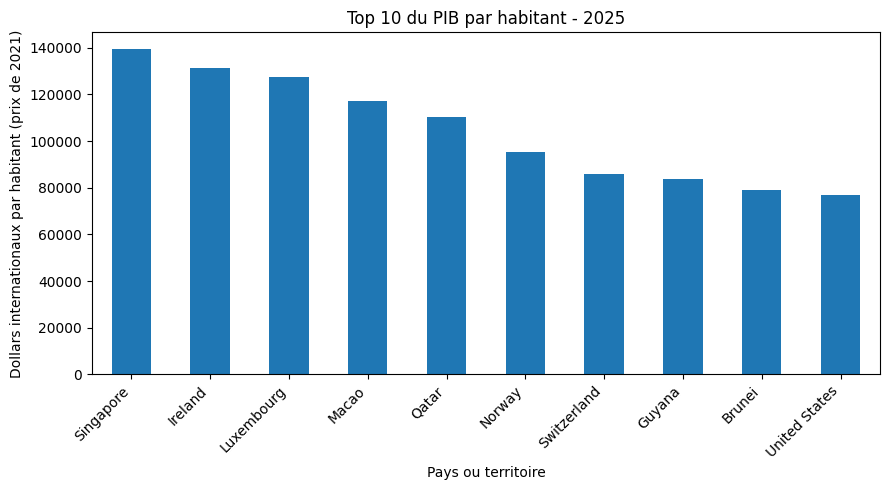

In [12]:
import matplotlib.pyplot as plt

# Critère adapté à ce CSV inspecté, incluant des territoires comme Macao.
latest_pays = latest.loc[latest["code"].str.len() == 3].copy()
top10 = latest_pays.sort_values("gdp_pc", ascending=False).head(10)
print(top10[["country", "gdp_pc"]].to_string(index=False))
ax = top10.plot(kind="bar", x="country", y="gdp_pc", legend=False, figsize=(9, 5))
ax.set_xlabel("Pays ou territoire")
ax.set_ylabel("Dollars internationaux par habitant (prix de 2021)")
ax.set_title(f"Top 10 du PIB par habitant - {latest_year}")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(out_dir / "gdp_top10.png", dpi=300)
plt.show()
plt.close()


**Résultat et interprétation.** Singapore arrive en tête de ce fichier (139592.610), suivi d’Ireland et Luxembourg. United States est dixième. Ce top 10 concerne tous les pays ou territoires disponibles, pas les huit pays de selection.

## Exercice 12 — Exporter un tableau propre

**Objectif.** Exporter uniquement les quatre colonnes demandées.

**Démarche.** Choisir explicitement les colonnes ; index=False évite d’ajouter les numéros de lignes de pandas au CSV.

In [13]:
selection[["country", "code", "year", "gdp_pc"]].to_csv(
    out_dir / "gdp_selection.csv",
    index=False
)
print("Export créé :", out_dir / "gdp_selection.csv")


Export créé : out/gdp_selection.csv


**Résultat et interprétation.** out/gdp_selection.csv contient huit lignes de données et quatre colonnes, sans colonne d’index supplémentaire.

## Exercice 13 — Interprétation finale

**Objectif.** Rédiger une interprétation de sept lignes.

**Démarche.** Citer les valeurs de la sélection de huit pays, distincte du top 10 mondial, puis annoncer les limites.

In [14]:
# L'année étudiée dans la copie locale est 2025.
# United States a le PIB par habitant le plus élevé de la sélection : 76 931,31.
# India a le plus faible : 10 039,07 dollars internationaux aux prix de 2021.
# La moyenne simple vaut 43 281,58 et la médiane 48 121,35 dans cette unité.
# France (55 124,54) est au-dessus de cette moyenne de huit pays.
# Le choix des huit pays influence ces résultats ; ce n'est pas une moyenne mondiale.
# Le PIB par habitant ne décrit ni les inégalités internes ni toutes les dimensions du développement.


**Résultat et interprétation.** Sept lignes fondées sur les résultats exécutés. Si vous utilisez un nouveau téléchargement, recalculer les valeurs et adapter ces commentaires.

## Question facultative 1 — Tracer seulement les huit pays sélectionnés.

**Objectif.** Tracer seulement les huit pays sélectionnés.

**Démarche.** Trier selection au lieu de latest_pays pour changer le périmètre de la figure.

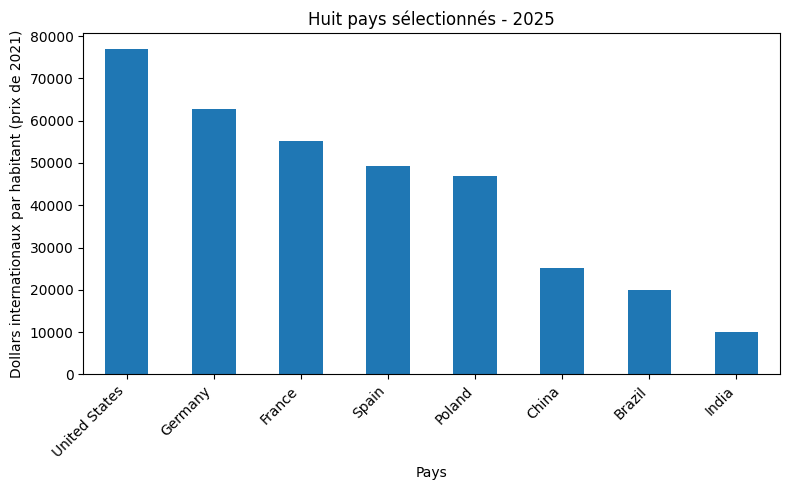

In [15]:
selection_triee = selection.sort_values("gdp_pc", ascending=False)
ax = selection_triee.plot(kind="bar", x="country", y="gdp_pc", legend=False, figsize=(8, 5))
ax.set_ylabel("Dollars internationaux par habitant (prix de 2021)")
ax.set_xlabel("Pays")
ax.set_title(f"Huit pays sélectionnés - {latest_year}")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(out_dir / "gdp_pays_selection.png", dpi=300)
plt.show()
plt.close()


**Résultat et interprétation.** United States est en tête de ces huit pays, mais pas du top 10 de tous les pays et territoires.

## Question facultative 2 — Comparer la France à trois pays.

**Objectif.** Comparer la France à trois pays.

**Démarche.** Filtrer les quatre lignes, puis soustraire la valeur française pour rendre le sens des écarts explicite.

In [16]:
comparaison = selection.loc[selection["country"].isin(
    ["France", "Germany", "United States", "China"]
)].copy()
valeur_france = comparaison.loc[comparaison["country"] == "France", "gdp_pc"].iloc[0]
comparaison["ecart_a_france"] = comparaison["gdp_pc"] - valeur_france
print(comparaison[["country", "gdp_pc", "ecart_a_france"]].to_string(index=False))


      country    gdp_pc  ecart_a_france
        China 25066.521      -30058.019
       France 55124.540           0.000
      Germany 62823.773        7699.233
United States 76931.310       21806.770


**Résultat et interprétation.** Germany et United States dépassent France ; China est en dessous. L’écart de France à elle-même vaut zéro.

## Question facultative 3 — Créer une colonne de booléens.

**Objectif.** Créer une colonne de booléens.

**Démarche.** Comparer chaque valeur à la même moyenne de sélection calculée à l’exercice 10.

In [17]:
selection["above_selection_mean"] = selection["gdp_pc"] > moyenne
print(selection[["country", "above_selection_mean"]].to_string(index=False))


      country  above_selection_mean
       Brazil                 False
        China                 False
       France                  True
      Germany                  True
        India                 False
       Poland                  True
        Spain                  True
United States                  True


**Résultat et interprétation.** True pour France, Germany, Poland, Spain et United States ; False pour Brazil, China et India.

## Question facultative 4 — Exporter le top 10.

**Objectif.** Exporter le top 10.

**Démarche.** Conserver les quatre colonnes documentées, sans index pandas.

In [18]:
top10[["country", "code", "year", "gdp_pc"]].to_csv(
    out_dir / "gdp_top10.csv", index=False
)
print("Top 10 exporté :", out_dir / "gdp_top10.csv")


Top 10 exporté : out/gdp_top10.csv


**Résultat et interprétation.** Un CSV de dix lignes, correspondant exactement au graphique du top 10.

## Question facultative 5 — Tracer la série française depuis 1990.

**Objectif.** Tracer la série française depuis 1990.

**Démarche.** Repartir de df, qui contient toutes les années, et non de latest. Trier les années avant de relier les points.

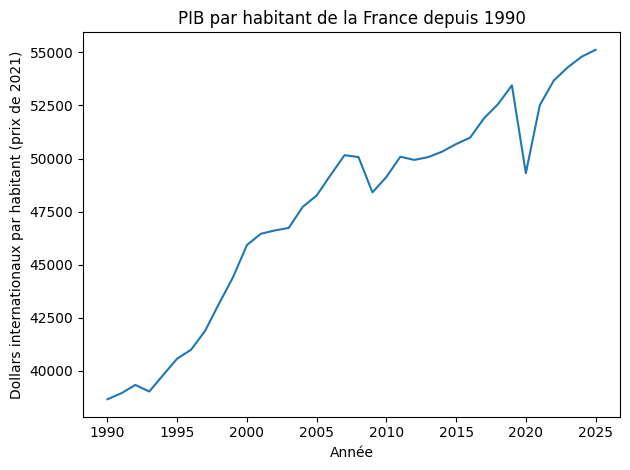

Années disponibles : 1990 2025


In [19]:
france_serie = df.loc[(df["country"] == "France") & (df["year"] >= 1990)].copy()
france_serie = france_serie.dropna(subset=["gdp_pc"]).sort_values("year")
ax = france_serie.plot(x="year", y="gdp_pc", legend=False)
ax.set_xlabel("Année")
ax.set_ylabel("Dollars internationaux par habitant (prix de 2021)")
ax.set_title("PIB par habitant de la France depuis 1990")
plt.tight_layout()
plt.savefig(out_dir / "gdp_france_depuis_1990.png", dpi=300)
plt.show()
plt.close()
print("Années disponibles :", france_serie["year"].min(), france_serie["year"].max())


**Résultat et interprétation.** La série fournie couvre 1990 à 2025. La trajectoire n’est pas une croissance uniforme : elle présente notamment des baisses à certaines dates.

## Question facultative 6 — Ajouter World lorsqu’il est disponible.

**Objectif.** Ajouter World lorsqu’il est disponible.

**Démarche.** Repartir de la liste de noms demandée et y ajouter World ; afficher aussi cette référence seule pour vérifier sa présence.

In [20]:
pays_avec_monde = pays_selection + ["World"]
selection_avec_monde = latest.loc[latest["country"].isin(pays_avec_monde)].copy()
monde = latest.loc[latest["country"] == "World", ["country", "gdp_pc"]]
if monde.empty:
    print("World n'est pas disponible pour cette année.")
else:
    print(monde.to_string(index=False))
print("Nombre de lignes avec World :", len(selection_avec_monde))


country   gdp_pc
  World 21913.51
Nombre de lignes avec World : 9


**Résultat et interprétation.** Dans la copie fournie, World est présent. Sa valeur est une référence agrégée ; ne pas calculer une moyenne de pays en l’ajoutant comme un pays supplémentaire.

## Question facultative 7 — Choisir manuellement une année.

**Objectif.** Choisir manuellement une année.

**Démarche.** 2020 existe dans le fichier. Créer un nouvel extrait pour préserver les résultats 2025 du mini-projet.

In [21]:
annee_choisie = 2020
tableau_2020 = df.loc[df["year"] == annee_choisie].dropna(subset=["gdp_pc"]).copy()
selection_2020 = tableau_2020.loc[tableau_2020["country"].isin(pays_selection)].copy()
print(selection_2020[["country", "year", "gdp_pc"]].to_string(index=False))
print("Nombre de pays en 2020 :", len(selection_2020))


      country  year     gdp_pc
       Brazil  2020 17327.5160
        China  2020 19215.1020
       France  2020 49311.3320
      Germany  2020 60299.5800
        India  2020  7186.8643
       Poland  2020 37852.8000
        Spain  2020 41553.4500
United States  2020 67406.8300
Nombre de pays en 2020 : 8


**Résultat et interprétation.** Huit pays en 2020 dans ce fichier. Changer l’année change le périmètre temporel : le signaler dans toute interprétation.

## Question facultative 8 — Calculer le rapport entre maximum et minimum.

**Objectif.** Calculer le rapport entre maximum et minimum.

**Démarche.** Diviser deux valeurs dans la même unité. Vérifier que le minimum est positif avant cette division.

In [22]:
if minimum > 0:
    rapport = maximum / minimum
    print(f"Rapport maximum / minimum : {rapport:.2f}")
else:
    print("Le rapport demandé nécessite un minimum strictement positif.")


Rapport maximum / minimum : 7.66


**Résultat et interprétation.** 7.66 : le maximum de la sélection représente environ 7.66 fois son minimum. Ce rapport n’a pas d’unité.

## Question facultative 9 — Importer l’espérance de vie et inspecter ses colonnes.

**Objectif.** Importer l’espérance de vie et inspecter ses colonnes.

**Démarche.** Utiliser également le CSV déjà présent dans le dépôt. La version en ligne est indiquée ; le corrigé utilise la copie locale jointe.

In [23]:
url_vie = "https://ourworldindata.org/grapher/life-expectancy.csv"
# Version en ligne : vie = pd.read_csv(url_vie)
vie = pd.read_csv("data/life-expectancy.csv")
print(vie.head())
print(vie.shape)
print(list(vie.columns))
vie = vie.rename(columns={
    "Entity": "country", "Code": "code", "Year": "year",
    "Life expectancy": "life_expectancy"
})
print("Dernière année de l'espérance de vie :", vie["year"].max())


        Entity Code  Year  Life expectancy
0  Afghanistan  AFG  1950          28.1563
1  Afghanistan  AFG  1951          28.5836
2  Afghanistan  AFG  1952          29.0138
3  Afghanistan  AFG  1953          29.4521
4  Afghanistan  AFG  1954          29.6975
(21565, 4)
['Entity', 'Code', 'Year', 'Life expectancy']
Dernière année de l'espérance de vie : 2023


**Résultat et interprétation.** 21565 lignes, 4 colonnes ; dernière année 2023. Ici l’indicateur se nomme Life expectancy, en années. Son année maximale diffère de celle du PIB.

## Question facultative 10 — Fusionner les deux indicateurs pour une même année.

**Objectif.** Fusionner les deux indicateurs pour une même année.

**Démarche.** Les dernières années diffèrent : chercher la dernière année commune avec valeurs présentes. Retirer les agrégats, puis fusionner sur le code et l’année. Une jointure interne conserve seulement les couples présents dans les deux tableaux.

In [24]:
gdp_complet = df.dropna(subset=["gdp_pc", "code"])
vie_complete = vie.dropna(subset=["life_expectancy", "code"])
annees_gdp = gdp_complet["year"].unique()
annees_communes = vie_complete.loc[vie_complete["year"].isin(annees_gdp), "year"]
annee_commune = annees_communes.max()
gdp_commun = gdp_complet.loc[
    (gdp_complet["year"] == annee_commune) & (gdp_complet["code"].str.len() == 3),
    ["country", "code", "year", "gdp_pc"]
]
vie_commune = vie_complete.loc[
    (vie_complete["year"] == annee_commune) & (vie_complete["code"].str.len() == 3),
    ["code", "year", "life_expectancy"]
]
fusion = gdp_commun.merge(vie_commune, on=["code", "year"], how="inner")
print("Année commune :", annee_commune)
print("Pays ou territoires appariés :", len(fusion))
print(fusion.head().to_string(index=False))
fusion.to_csv(out_dir / "gdp_esperance_vie.csv", index=False)


Année commune : 2023
Pays ou territoires appariés : 196
    country code  year     gdp_pc  life_expectancy
Afghanistan  AFG  2023  1983.8126          66.0346
    Albania  ALB  2023 20501.6460          79.6019
    Algeria  DZA  2023 15159.3240          76.2610
    Andorra  AND  2023 64631.2970          84.0406
     Angola  AGO  2023  8597.5390          64.6170


**Résultat et interprétation.** L’année commune est 2023. Chaque ligne appariée contient un PIB et une espérance de vie pour la même année. Ce rapprochement descriptif ne démontre pas qu’un indicateur cause l’autre.